# 🐍 Modern Python Introduction: Fundamentals, Type Hints, and OOP

This interactive guide brings together the key concepts for getting started in professional software development using **modern Python**. Throughout this notebook, you will learn how to write clean, readable, and strongly typed code using today's industry best practices.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/secorto/notebooks/blob/main/spanish/poo-python.ipynb)


## Diagram setup

For this notebook, we will use PlantUML, so install the extension by running the following cells

In [ ]:
%pip install iplantuml

In [2]:
import iplantuml

## 1. The Concept of Objects in Python

Object-oriented programming (OOP) starts from the concept of "objects" as essential building blocks. An object contains structured information (attributes) and functions capable of operating on it (methods).

Unlike other languages, in Python we must be explicit. In every instance method, it is mandatory to receive a reference to the object itself, which by strict convention we call `self` (the equivalent of `this` in TypeScript, C++ or Java).


Writing output for /home/scot3004/Proyectos/notebooks/english/570fd6ad-a2f8-488c-97ed-1fa7c8a412a5.uml to 570fd6ad-a2f8-488c-97ed-1fa7c8a412a5.svg


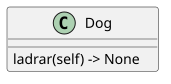

In [ ]:
%%plantuml

@startuml
Dog : bark(self) -> None
@enduml

In [ ]:
class Dog:
    def bark(self) -> None:
        print("Woof woof!")

# Instantiate the class and execute its method
my_dog = Dog()
my_dog.bark()

Woof woof!


If you omit `self` as the first parameter of an instance method, Python will raise a type error (`TypeError`) when you try to call it, indicating that an unexpected implicit argument was passed.

### Static Methods
If you need to group a utility method inside a class that does not need to access the properties of the object or the class, you can use the `@staticmethod` decorator to do without `self`.

Writing output for /home/scot3004/Proyectos/notebooks/english/00923fae-fa28-4c6c-82da-ad1fdc7ccf08.uml to 00923fae-fa28-4c6c-82da-ad1fdc7ccf08.svg


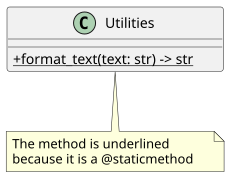

In [5]:
%%plantuml

@startuml
skinparam classAttributeIconSize 0

class Utilities {
  {static} +format_text(text: str) -> str
}

note bottom of Utilities
  The method is underlined
  because it is a @staticmethod
end note
@enduml


In [6]:
class Utilities:
    @staticmethod
    def format_text(text: str) -> str:
        return text.strip().capitalize()

print(Utilities.format_text("   hello world from python   "))

Hello world from python


## 2. Modern Data Structuring: Type Hints and `@dataclass`

Traditionally, in Python, object properties were defined dynamically inside a special constructor called `__init__`. However, the modern ecosystem prefers optional static typing (**Type Hints - PEP 484**) to provide robust autocomplete and error detection before execution.

Starting with Python 3.7, we have the `@dataclass` decorator. This modern approach radically simplifies repetitive boilerplate by auto-generating constructors, comparators, and readable representations natively.


Writing output for /home/scot3004/Proyectos/notebooks/english/47909f73-6519-41e3-9409-970a732dd7af.uml to 47909f73-6519-41e3-9409-970a732dd7af.svg


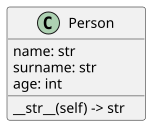

In [7]:
%%plantuml

@startuml
Person : name: str
Person : surname: str
Person : age: int
Person : __str__(self) -> str
@enduml

In [8]:
from dataclasses import dataclass

@dataclass
class Person:
    # We define attributes using Type Hints clearly and explicitly
    name: str
    surname: str
    age: int

    # The special __str__ method defines what to display when using print()
    def __str__(self) -> str:
        return f"{self.name} {self.surname} ({self.age} years)"

# Direct creation thanks to the constructor auto-generated by @dataclass
developer = Person(name="Sergio", surname="Orozco", age=30)
print(developer)

Sergio Orozco (30 years)


## 3. Operator Overloading and Magic Methods

Python exposes a set of special methods delimited by a double underscore before and after (`__`), commonly called *magic methods* or *dunder methods*. These allow you to modify the intrinsic behavior of the language for your own objects, such as defining what happens when you add or subtract two instances using the traditional `+` and `-` operators.


Writing output for /home/scot3004/Proyectos/notebooks/english/9d42f440-a0d8-4183-ba28-6b8becfce76f.uml to 9d42f440-a0d8-4183-ba28-6b8becfce76f.svg


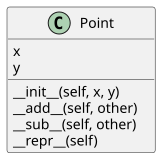

In [9]:
%%plantuml

@startuml
Point : x
Point : y

Point : __init__(self, x, y)
Point : __add__(self, other)
Point : __sub__(self, other)
Point : __repr__(self)
@enduml

In [10]:
from __future__ import annotations
class Point:
    def __init__(self, x: float, y: float) -> None:
        self.x = x
        self.y = y

    # Operator overloading for +
    def __add__(self, other: 'Point') -> Point:
        return Point(self.x + other.x, self.y + other.y)

    # Operator overloading for -
    def __sub__(self, other: 'Point') -> Point:
        return Point(self.x - other.x, self.y - other.y)

    # Development representation of the object
    def __repr__(self) -> str:
        return f"Point({self.x}, {self.y})"

p1 = Point(5, 12)
p2 = Point(3, 4)

print("Sum of points:", p1 + p2)
print("Difference of points:", p1 - p2)

Sum of points: Point(8, 16)
Difference of points: Point(2, 8)


## 4. Inheritance, Polymorphism, and Relationships Between Classes

Inheritance allows you to structure specializations by sharing common logic from an ancestor or base class. A derived class inherits attributes and methods, allowing you to extend functionality or redefine specific behaviors (Polymorphism).


Writing output for /home/scot3004/Proyectos/notebooks/english/f1888ded-9059-4d78-b624-f01bcb75a657.uml to f1888ded-9059-4d78-b624-f01bcb75a657.svg


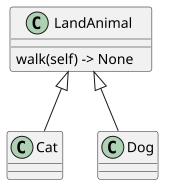

In [11]:
%%plantuml

@startuml
LandAnimal : walk(self) -> None

LandAnimal <|-- Cat
LandAnimal <|-- Dog
@enduml


In [12]:
class LandAnimal:
    def walk(self) -> None:
        print("The animal moves across the surface.")

class Dog(LandAnimal):
    # Inherits the walking behavior unchanged
    pass

class Cat(LandAnimal):
    # Polymorphism: overriding the method to specialize it
    def walk(self) -> None:
        print("The cat walks with absolute stealth 🐾")

print("Dog behavior:")
p = Dog()
p.walk()

print("\nCat behavior:")
g = Cat()
g.walk()

Dog behavior:
The animal moves across the surface.

Cat behavior:
The cat walks with absolute stealth 🐾


### Multiple Inheritance and the Diamond Problem
Python is one of the few high-level languages that supports multiple inheritance natively. When an ambiguity arises because two base classes share a common ancestor and override the same method (the Diamond Problem), Python applies a rigorous algorithm called **MRO (Method Resolution Order)** to decide which implementation to execute based on the declaration order.


Writing output for /home/scot3004/Proyectos/notebooks/english/6db2c5a8-79a9-4c1c-849f-7fbb32591b33.uml to 6db2c5a8-79a9-4c1c-849f-7fbb32591b33.svg


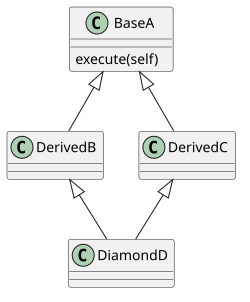

In [13]:
%%plantuml
@startuml
BaseA : execute(self)

BaseA <|-- DerivedB
BaseA <|-- DerivedC
DerivedB <|-- DiamondD
DerivedC <|-- DiamondD
@enduml

In [14]:
class BaseA:
    def execute(self) -> None:
        print("Executing from BaseA")

class DerivedB(BaseA):
    def execute(self) -> None:
        print("Executing from DerivedB")

class DerivedC(BaseA):
    def execute(self) -> None:
        print("Executing from DerivedC")

# The declaration order (DerivedB first) determines priority in the MRO
class DiamondD(DerivedB, DerivedC):
    pass

instance_d = DiamondD()
instance_d.execute()

# We can inspect the exact resolution order using __mro__
print("\nMRO order of the class:", [cls.__name__ for cls in DiamondD.__mro__])

Executing from DerivedB

MRO order of the class: ['DiamondD', 'DerivedB', 'DerivedC', 'BaseA', 'object']


## 5. The Philosophy of the Language: Duck Typing

In purely static languages, for two objects to be treated the same in a function, they must implement the same interface or inherit from the same class. Python uses **Duck Typing**: *"If it walks like a duck, quacks like a duck, then we treat it like a duck"*.

If a section of your code needs to invoke a specific method (such as `.fly()`), any object that provides that method can be used, regardless of its genealogy.


Writing output for /home/scot3004/Proyectos/notebooks/english/0ebca894-8af3-43cc-a465-212da26ebc1c.uml to 0ebca894-8af3-43cc-a465-212da26ebc1c.svg


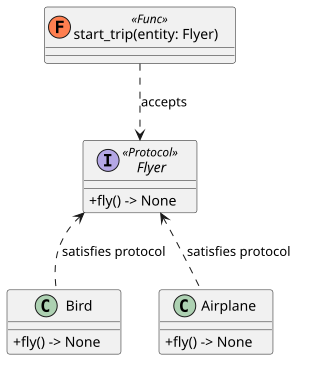

In [15]:
%%plantuml

@startuml
skinparam classAttributeIconSize 0

interface Flyer <<Protocol>> {
  +fly() -> None
}

class Bird {
  +fly() -> None
}

class Airplane {
  +fly() -> None
}

class "start_trip(entity: Flyer)" as Function <<(F,#FF7F50) Func>> {
}

' Structural compatibility relationship (implicit implementation)
Flyer <.. Bird : satisfies protocol
Flyer <.. Airplane : satisfies protocol

' Dependency of the function on the protocol
Function ..> Flyer : accepts
@enduml


In [16]:
from typing import Protocol

# We define a Protocol (modern structural interface in Python)
class Flyer(Protocol):
    def fly(self) -> None: ...

class Bird:
    def fly(self) -> None:
        print("The bird flaps its wings in the sky.")

class Airplane:
    def fly(self) -> None:
        print("The airplane starts its fuel turbines.")

# This function accepts any object that satisfies the Flyer protocol
def start_trip(entity: Flyer) -> None:
    entity.fly()

# Both classes are structurally compatible without explicit inheritance
start_trip(Bird())
start_trip(Airplane())

The bird flaps its wings in the sky.
The airplane starts its fuel turbines.


## Conclusions and Next Steps

Congratulations! You have mastered the basics of software modeling and engineering in modern Python. Writing applications by structuring your data with `dataclasses` and defining clean contracts with `Type Hints` will prepare you to interact efficiently with professional frameworks such as FastAPI, Pydantic, or SQLAlchemy.

### Recommended resources to expand your knowledge:
- **Official Type Hints Documentation:** [PEP 484](https://peps.python.org/pep-0484/)
- **Design Patterns in Python:** Explore advanced implementations at [Refactoring Guru](https://refactoring.guru/design-patterns/python)
- **Data ecosystem:** Interactive development and modeling course on [DataCamp](https://www.datacamp.com/courses/intro-to-python-for-data-science)
